In [2]:
import sys

!{sys.executable} -m pip install neuralforecast

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
   ---------------------------------------- 0.0/853.0 kB ? eta -:--:--
   ---------------------------------------- 853.0/853.0 kB 7.6 MB/s  0:00:00
   ---------------------------------------- 0.0/29.4 MB ? eta -:--:--
   - -------------------------------------- 0.8/29.4 MB 4.8 MB/s eta 0:00:06
   -- ------------------------------------- 2.1/29.4 MB 5.6 MB/s eta 0:00:05
   ---- ----------------------------------- 3.1/29.4 MB 5.4 MB/s eta 0:00:05
   ----- ---------------------------------- 4.2/29.4 MB 5.2 MB/s eta 0:00:05
   ------ --------------------------------- 5.0/29.4 MB 5.0 MB/s eta 0:00:05
   -------- ------------------------------- 6.0/29.4 MB 5.0 MB/s eta 0:00:05
   --------- ------------------------------ 7.1/29.4 MB 4.9 MB/s eta 0:00:05
   ----------- ---------------------------- 8.1/29.4 MB 5.0 MB/s eta 0:00:05
   ------------ --------------------------- 9.4/29.4 MB 5.0 MB/s eta 0:00:05
   -------------

  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
darts 0.44.0 requires holidays>=0.11.1, which is not installed.
darts 0.44.0 requires nfoursid>=1.0.0, which is not installed.
darts 0.44.0 requires pyod>=0.9.5, which is not installed.
darts 0.44.0 requires xarray>=0.17.0, which is not installed.
keras-tuner 1.4.8 requires kt-legacy, which is not installed.
tensorboard 2.10.1 requires protobuf<3.20,>=3.9.2, but you have protobuf 3.20.3 which is incompatible.
tensorflow 2.10.0 requires protobuf<3.20,>=3.9.2, but you have protobuf 3.20.3 which is incompatible.

[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: C:\Users\Administrador\tf-gpu-env\Scripts\python.exe -m pip install --upgrade pip


In [3]:
import neuralforecast

print("NeuralForecast instalado correctamente")
print("Python utilizado:", sys.executable)

C:\Users\Administrador\tf-gpu-env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-11-14 21:47:07,751	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2026-11-14 21:47:08,654	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


NeuralForecast instalado correctamente
Python utilizado: C:\Users\Administrador\tf-gpu-env\Scripts\python.exe


Cargando datos...
Meses disponibles: 309 (2000-11 a 2026-07)

Entrenamiento: 216 meses (2000-11 a 2018-10)
Validación   :  46 meses (2018-11 a 2022-08)
Prueba       :  47 meses (2022-09 a 2026-07)

Ventanas -> entrenamiento: 169 | validación: 35

Entrenando modelo...

Epoch 35: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.

Epoch 47: ReduceLROnPlateau reducing learning rate to 7.500000356230885e-05.

Epoch 65: ReduceLROnPlateau reducing learning rate to 3.7500001781154424e-05.

Epoch 78: ReduceLROnPlateau reducing learning rate to 1.8750000890577212e-05.

Epoch 86: ReduceLROnPlateau reducing learning rate to 1e-05.
Epoch 95: early stopping
Restoring model weights from the end of the best epoch: 70.
Mejor época: 70 de 95 ejecutadas (val_loss 0.6423)

========== RESULTADOS ==========
Validación: 36 meses evaluados (2019-09 a 2022-08)
   N-HiTS           MAE   2,155.2 | RMSE   2,991.5 | MAPE   55.2%
   Base estacional  MAE   2,429.0 | RMSE   3,336.7 | MAPE   67.6%
Pru

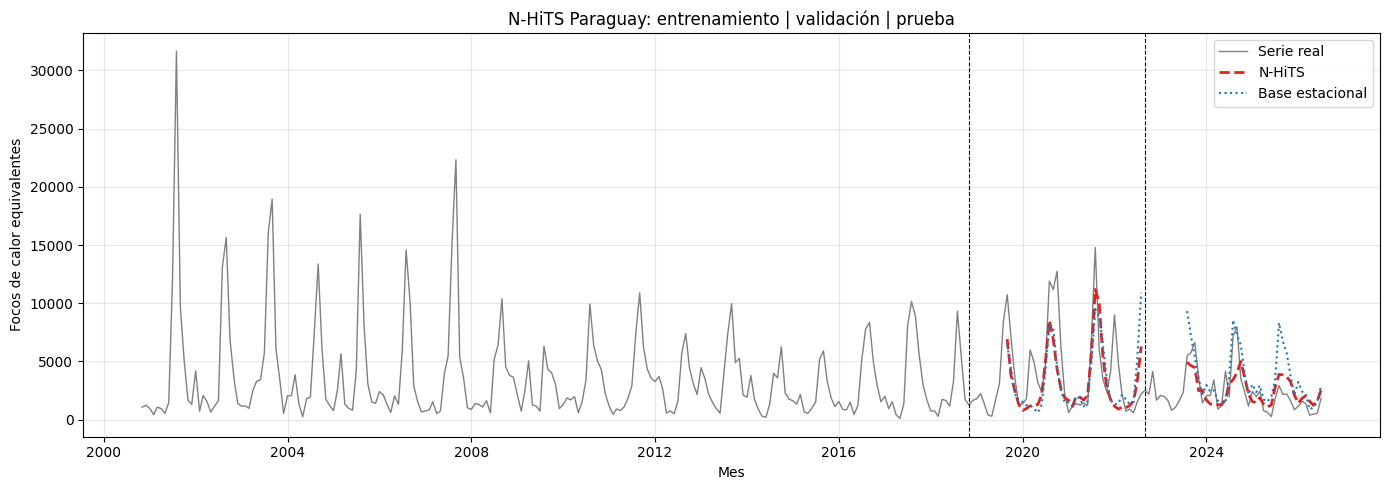


Reentrenando con toda la serie...

========== ENTRENAMIENTO COMPLETADO ==========
Modelo guardado en: C:\Users\Administrador\Downloads\models\nhits
 - loss_curve.png
 - metadata.json
 - nbeats_final.keras
 - validation.png


In [2]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")

# ============================================================
# CONFIGURACIÓN
# ============================================================
ROOT = Path.home() / "Downloads"
DATA_PATH = ROOT / "tabla_armonizada.csv"
MODEL_DIR = ROOT / "models" / "nhits"

HORIZON = 12
INPUT_SIZE = 36
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15          # el 15 % restante es prueba
POOL_SIZES, FREQ_DOWN = [4, 2, 1], [4, 2, 1]   # knots de salida: 12//4=3, 12//2=6, 12
N_BLOCKS = len(POOL_SIZES)
WIDTH, N_LAYERS, DROPOUT = 64, 2, 0.2
MAX_EPOCHS, PATIENCE, BATCH, LR, SEED = 300, 25, 32, 3e-4, 42
REG_TYPE = "l2"   # opciones: None, "l1", "l2", "l1_l2"
REG_VALUE = 1e-4

MODEL_DIR.mkdir(parents=True, exist_ok=True)
keras.utils.set_random_seed(SEED)

# ============================================================
# 1. DATOS
# ============================================================
print("Cargando datos...")
df = pd.read_csv(DATA_PATH)
df["mes"] = pd.to_datetime(df["mes"].astype(str))
df = df[df["mes"] < pd.Timestamp.today().to_period("M").to_timestamp()]
if "provisorio" in df.columns:
    df = df[~df["provisorio"].astype(str).str.lower().isin(["true", "1", "si", "sí"])]

series = df.groupby("mes", as_index=False)["conteo_eq"].sum().sort_values("mes")
series = (series.set_index("mes").asfreq("MS", fill_value=0)
          .rename_axis("ds").reset_index())
series["y"] = series["conteo_eq"].astype(float)
series["unique_id"] = "PARAGUAY"
data = series[["unique_id", "ds", "y"]].copy().reset_index(drop=True)

if not np.isfinite(data["y"]).all() or (data["y"] < 0).any():
    raise ValueError("La serie contiene valores no finitos o negativos.")

n = len(data)
y_all = data["y"].to_numpy()
ds = data["ds"]
print(f"Meses disponibles: {n} ({ds.iloc[0]:%Y-%m} a {ds.iloc[-1]:%Y-%m})")

# ============================================================
# 2. SPLIT CRONOLÓGICO 70 / 15 / 15
# ============================================================
i_val = int(n * TRAIN_FRAC)
i_test = i_val + int(n * VAL_FRAC)
print()
for nombre, a, b in [("Entrenamiento", 0, i_val), ("Validación", i_val, i_test), ("Prueba", i_test, n)]:
    print(f"{nombre:<13}: {b - a:>3} meses ({ds.iloc[a]:%Y-%m} a {ds.iloc[b - 1]:%Y-%m})")
if i_val < INPUT_SIZE + HORIZON or i_test - i_val < HORIZON or n - i_test < HORIZON:
    raise ValueError("Algún tramo es demasiado corto para INPUT_SIZE + HORIZON.")

# ============================================================
# 3. ESCALA (solo con entrenamiento) Y VENTANAS
# ============================================================
z_ref = np.log1p(y_all[:i_val])
MU, SD = float(z_ref.mean()), float(z_ref.std())

def esc(y):
    return ((np.log1p(y) - MU) / SD).astype("float32")

def des(z):
    return np.maximum(np.expm1(z * SD + MU), 0)

def ventanas(z, n_in, n_out):
    X, Y = [], []
    for i in range(len(z) - n_in - n_out + 1):
        X.append(z[i:i + n_in])
        Y.append(z[i + n_in:i + n_in + n_out])
    return np.array(X, dtype="float32"), np.array(Y, dtype="float32")

z_all = esc(y_all)
X_tr, Y_tr = ventanas(z_all[:i_val], INPUT_SIZE, HORIZON)                  # objetivos dentro de entrenamiento
X_val, Y_val = ventanas(z_all[i_val - INPUT_SIZE:i_test], INPUT_SIZE, HORIZON)  # objetivos dentro de validación
print(f"\nVentanas -> entrenamiento: {len(X_tr)} | validación: {len(X_val)}")

# ============================================================
# 4. N-HiTS (Keras)
# ============================================================
def matriz_interp(k, h):
    """Matriz (k, h) de interpolación lineal de k puntos a h pasos."""
    W = np.zeros((k, h), dtype="float32")
    if k == 1:
        W[0, :] = 1.0
        return W
    pos = np.linspace(0, h - 1, k)
    for t in range(h):
        j = min(max(np.searchsorted(pos, t, side="right") - 1, 0), k - 2)
        w = (t - pos[j]) / (pos[j + 1] - pos[j])
        W[j, t], W[j + 1, t] = 1 - w, w
    return W

def construir():
    entrada = keras.Input(shape=(INPUT_SIZE,))
    residual, pron = entrada, None
    for k_pool, k_freq in zip(POOL_SIZES, FREQ_DOWN):
        h = residual
        if k_pool > 1:                                   # muestreo multi-tasa
            h = layers.Reshape((INPUT_SIZE, 1))(h)
            h = layers.MaxPooling1D(pool_size=k_pool, strides=k_pool, padding="same")(h)
            h = layers.Flatten()(h)
        # Regularización
        if REG_TYPE == "l1":
            regularizer = keras.regularizers.l1(REG_VALUE)
        
        elif REG_TYPE == "l2":
            regularizer = keras.regularizers.l2(REG_VALUE)
        
        elif REG_TYPE == "l1_l2":
            regularizer = keras.regularizers.l1_l2(
                l1=REG_VALUE,
                l2=REG_VALUE
            )
        
        else:
            regularizer = None
        
        for _ in range(N_LAYERS):
            h = layers.Dense(
                WIDTH,
                activation="relu",
                kernel_regularizer=regularizer
            )(h)
        
            h = layers.Dropout(DROPOUT)(h)
        back = layers.Dense(INPUT_SIZE)(h)
        n_knots = max(HORIZON // k_freq, 1)
        knots = layers.Dense(n_knots)(h)
        interp = layers.Dense(HORIZON, use_bias=False, trainable=False)   # interpolación fija
        fore = interp(knots)
        interp.set_weights([matriz_interp(n_knots, HORIZON)])
        residual = layers.Subtract()([residual, back])
        pron = fore if pron is None else layers.Add()([pron, fore])
    m = keras.Model(entrada, pron)
    m.compile(optimizer=keras.optimizers.Adam(LR), loss="mae")
    return m

print("\nEntrenando modelo...")
model = construir()
hist = model.fit(
    X_tr, Y_tr, validation_data=(X_val, Y_val),
    epochs=MAX_EPOCHS, batch_size=BATCH, verbose=0,
    callbacks=[
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=8,
            min_lr=1e-5,
            verbose=1
        ),
    
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=PATIENCE,
            restore_best_weights=True,
            verbose=1
        )
    ],
)
best_epoch = int(np.argmin(hist.history["val_loss"])) + 1
print(f"Mejor época: {best_epoch} de {len(hist.history['val_loss'])} ejecutadas "
      f"(val_loss {min(hist.history['val_loss']):.4f})")

# ============================================================
# 5. EVALUACIÓN EN VALIDACIÓN Y PRUEBA
# ============================================================
def evaluar(modelo, a, b):
    """Bloques de HORIZON meses sin solaparse, anclados al final de [a, b).
    El input siempre es el pasado real; la base usa solo datos anteriores a cada bloque."""
    k = (b - a) // HORIZON
    ini = b - k * HORIZON
    act, prd, bas = [], [], []
    for o in range(ini, b, HORIZON):
        x = esc(y_all[o - INPUT_SIZE:o])[None, :]
        prd.append(des(modelo.predict(x, verbose=0)[0]))
        act.append(y_all[o:o + HORIZON])
        pasado = data.iloc[:o]
        bas.append([pasado.loc[pasado["ds"].dt.month == m, "y"].tail(5).mean()
                    for m in ds.dt.month.iloc[o:o + HORIZON]])
    return ini, np.concatenate(act), np.concatenate(prd), np.concatenate(bas)

def metricas(a, p):
    mae = float(np.mean(np.abs(a - p)))
    rmse = float(np.sqrt(np.mean((a - p) ** 2)))
    mape = float(np.mean(np.abs(a - p) / np.maximum(np.abs(a), 1e-8)) * 100)
    return mae, rmse, mape

res = {}
print("\n========== RESULTADOS ==========")
for nombre, a, b in [("Validación", i_val, i_test), ("Prueba", i_test, n)]:
    ini, act, prd, bas = evaluar(model, a, b)
    res[nombre] = (ini, act, prd, bas)
    print(f"{nombre}: {len(act)} meses evaluados ({ds.iloc[ini]:%Y-%m} a {ds.iloc[b - 1]:%Y-%m})")
    for etiqueta, p in [("N-HiTS", prd), ("Base estacional", bas)]:
        mae, rmse, mape = metricas(act, p)
        print(f"   {etiqueta:<16} MAE {mae:>9,.1f} | RMSE {rmse:>9,.1f} | MAPE {mape:>6.1f}%")

# ============================================================
# 6. GRÁFICO
# ============================================================
ini_t, act_t, prd_t, bas_t = res["Prueba"]
ini_v, act_v, prd_v, bas_v = res["Validación"]
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(ds, y_all, color="grey", lw=1, label="Serie real")
ax.axvline(ds.iloc[i_val], color="black", ls="--", lw=0.8)
ax.axvline(ds.iloc[i_test], color="black", ls="--", lw=0.8)
for ini, prd, bas, tag in [(ini_v, prd_v, bas_v, ""), (ini_t, prd_t, bas_t, "")]:
    f = ds.iloc[ini:ini + len(prd)]
    ax.plot(f, prd, color="tab:red", lw=2, ls="--", label="N-HiTS" if ini == ini_v else None)
    ax.plot(f, bas, color="tab:blue", lw=1.5, ls=":", label="Base estacional" if ini == ini_v else None)
ax.set_title("N-HiTS Paraguay: entrenamiento | validación | prueba")
ax.set_xlabel("Mes"); ax.set_ylabel("Focos de calor equivalentes")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig(MODEL_DIR / "validation.png", dpi=150)
plt.show()

# ============================================================
# 7. REENTRENAR CON TODA LA SERIE Y GUARDAR
# ============================================================
print("\nReentrenando con toda la serie...")
X_all, Y_all = ventanas(z_all, INPUT_SIZE, HORIZON)
epochs_final = max(1, round(best_epoch * len(X_all) / len(X_tr)))   # mismos pasos de gradiente totales
final_model = construir()
final_model.fit(X_all, Y_all, epochs=epochs_final, batch_size=BATCH, verbose=0)
final_model.save(MODEL_DIR / "nbeats_final.keras")

m_val = metricas(res["Validación"][1], res["Validación"][2])
m_test = metricas(res["Prueba"][1], res["Prueba"][2])
metadata = {
    "model": "N-HiTS (Keras)", "series": "PARAGUAY", "frequency": "monthly",
    "horizon": HORIZON, "input_size": INPUT_SIZE,
    "n_blocks": N_BLOCKS, "width": WIDTH, "n_layers": N_LAYERS,
    "split": {"train": [f"{ds.iloc[0]:%Y-%m}", f"{ds.iloc[i_val - 1]:%Y-%m}"],
              "val": [f"{ds.iloc[i_val]:%Y-%m}", f"{ds.iloc[i_test - 1]:%Y-%m}"],
              "test": [f"{ds.iloc[i_test]:%Y-%m}", f"{ds.iloc[-1]:%Y-%m}"]},
    "best_epoch": best_epoch, "epochs_final": epochs_final,
    "scaler": {"transform": "log1p + estandarización (solo entrenamiento)", "mu": MU, "sd": SD},
    "val": {"mae": m_val[0], "rmse": m_val[1], "mape": m_val[2]},
    "test": {"mae": m_test[0], "rmse": m_test[1], "mape": m_test[2]},
    "random_seed": SEED,
    "pool_sizes": POOL_SIZES, "freq_downsample": FREQ_DOWN,
}
with open(MODEL_DIR / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4, ensure_ascii=False)

print("\n========== ENTRENAMIENTO COMPLETADO ==========")
print(f"Modelo guardado en: {MODEL_DIR}")
for p in MODEL_DIR.iterdir():
    print(" -", p.name)

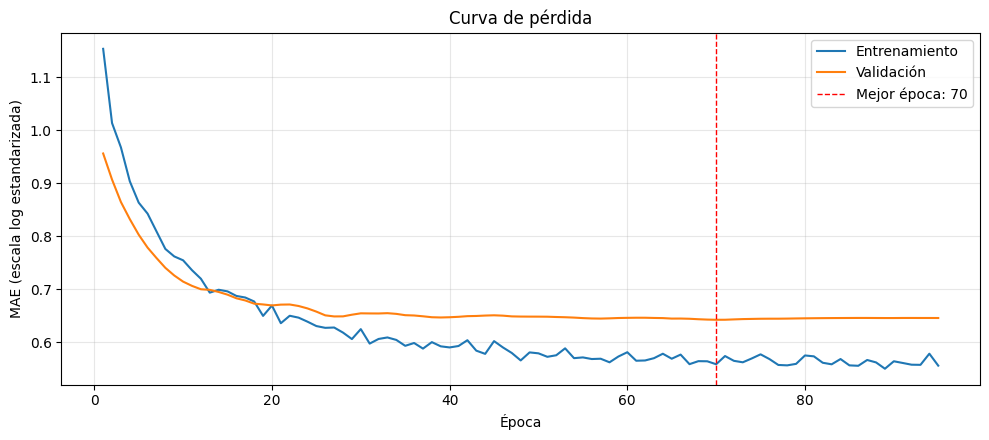

Pérdida entren. -> época 1: 1.154 | mejor época: 0.558 | última: 0.556
Pérdida valid.  -> época 1: 0.956 | mejor época: 0.642 | última: 0.646
Pasos por época: 6 | parámetros: 23,001


In [3]:
import numpy as np
import matplotlib.pyplot as plt

h = hist.history
ep = np.arange(1, len(h["loss"]) + 1)
mejor = int(np.argmin(h["val_loss"])) + 1

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(ep, h["loss"], label="Entrenamiento")
ax.plot(ep, h["val_loss"], label="Validación")
ax.axvline(mejor, color="red", ls="--", lw=1, label=f"Mejor época: {mejor}")
ax.set_xlabel("Época"); ax.set_ylabel("MAE (escala log estandarizada)")
ax.set_title("Curva de pérdida"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(MODEL_DIR / "loss_curve.png", dpi=150)
plt.show()

print(f"Pérdida entren. -> época 1: {h['loss'][0]:.3f} | mejor época: {h['loss'][mejor-1]:.3f} | última: {h['loss'][-1]:.3f}")
print(f"Pérdida valid.  -> época 1: {h['val_loss'][0]:.3f} | mejor época: {h['val_loss'][mejor-1]:.3f} | última: {h['val_loss'][-1]:.3f}")
print(f"Pasos por época: {int(np.ceil(len(X_tr) / BATCH))} | parámetros: {model.count_params():,}")

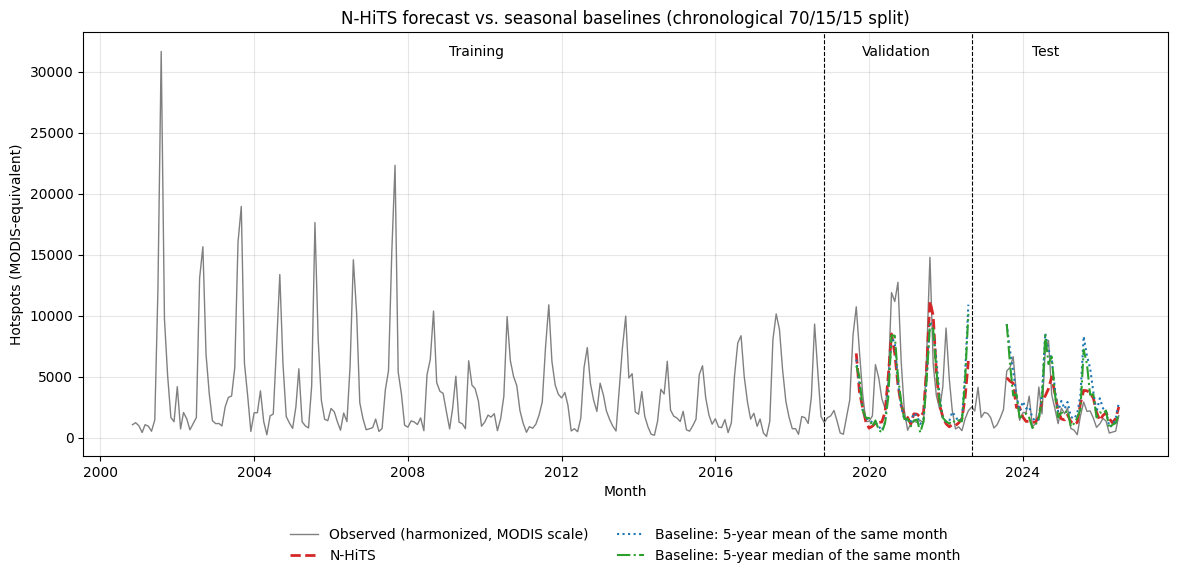

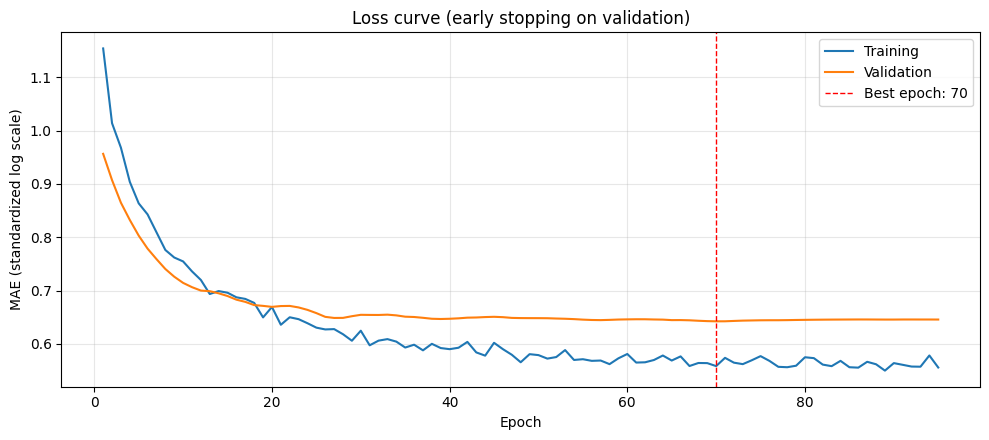

In [4]:
from pathlib import Path
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

ini_v, act_v, prd_v, bas_v = res["Validación"]
ini_t, act_t, prd_t, bas_t = res["Prueba"]

def base_mediana(o):
    pasado = data.iloc[:o]
    return [pasado.loc[pasado["ds"].dt.month == m, "y"].tail(5).median()
            for m in ds.dt.month.iloc[o:o + HORIZON]]

# ---- Fig. F1: forecast vs. baselines ----
fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(ds, y_all, color="grey", lw=1, label="Observed (harmonized, MODIS scale)")
ax.axvline(ds.iloc[i_val], color="black", ls="--", lw=0.8)
ax.axvline(ds.iloc[i_test], color="black", ls="--", lw=0.8)
for k, (ini, prd, bas) in enumerate([(ini_v, prd_v, bas_v), (ini_t, prd_t, bas_t)]):
    fechas = ds.iloc[ini:ini + len(prd)]
    med = np.concatenate([base_mediana(o) for o in range(ini, ini + len(prd), HORIZON)])
    ax.plot(fechas, prd, color="tab:red", lw=2, ls="--", label="N-HiTS" if k == 0 else None)
    ax.plot(fechas, bas, color="tab:blue", lw=1.5, ls=":", label="Baseline: 5-year mean of the same month" if k == 0 else None)
    ax.plot(fechas, med, color="tab:green", lw=1.5, ls="-.", label="Baseline: 5-year median of the same month" if k == 0 else None)
for x0, x1, txt in [(ds.iloc[0], ds.iloc[i_val - 1], "Training"),
                    (ds.iloc[i_val], ds.iloc[i_test - 1], "Validation"),
                    (ds.iloc[i_test], ds.iloc[-1], "Test")]:
    ax.text(x0 + (x1 - x0) / 2, 0.97, txt, transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=10)
ax.set_title("N-HiTS forecast vs. seasonal baselines (chronological 70/15/15 split)")
ax.set_xlabel("Month"); ax.set_ylabel("Hotspots (MODIS-equivalent)")
ax.grid(alpha=0.3)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)
fig.savefig(FIG / "fig_forecast_validation.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- Fig. F2: loss curve ----
h = hist.history
ep = np.arange(1, len(h["loss"]) + 1)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(ep, h["loss"], label="Training")
ax.plot(ep, h["val_loss"], label="Validation")
ax.axvline(best_epoch, color="red", ls="--", lw=1, label=f"Best epoch: {best_epoch}")
ax.set_xlabel("Epoch"); ax.set_ylabel("MAE (standardized log scale)")
ax.set_title("Loss curve (early stopping on validation)")
ax.grid(alpha=0.3); ax.legend()
fig.tight_layout()
fig.savefig(FIG / "fig_loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()

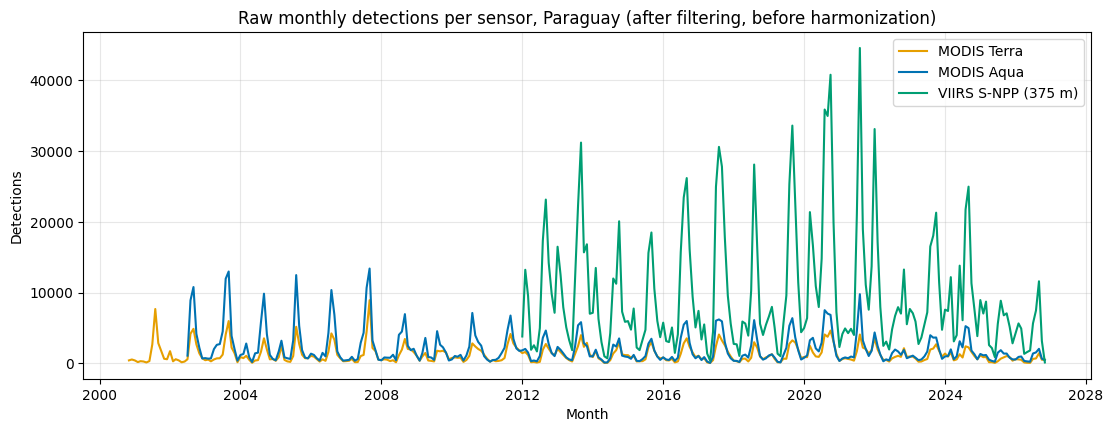

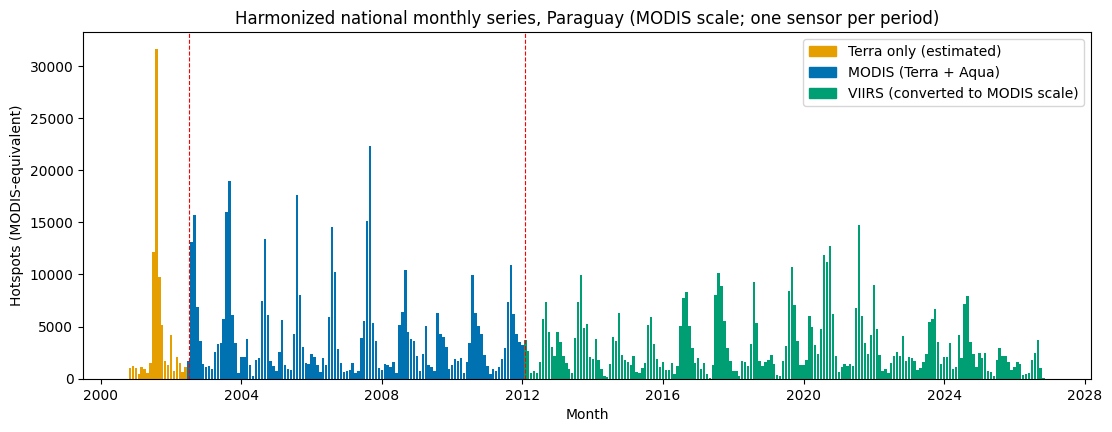

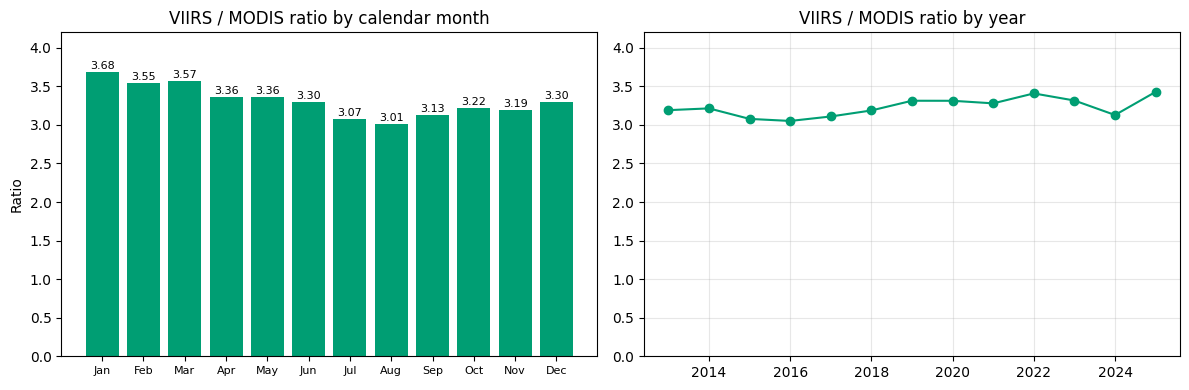

bias +3.1% | r = 0.993


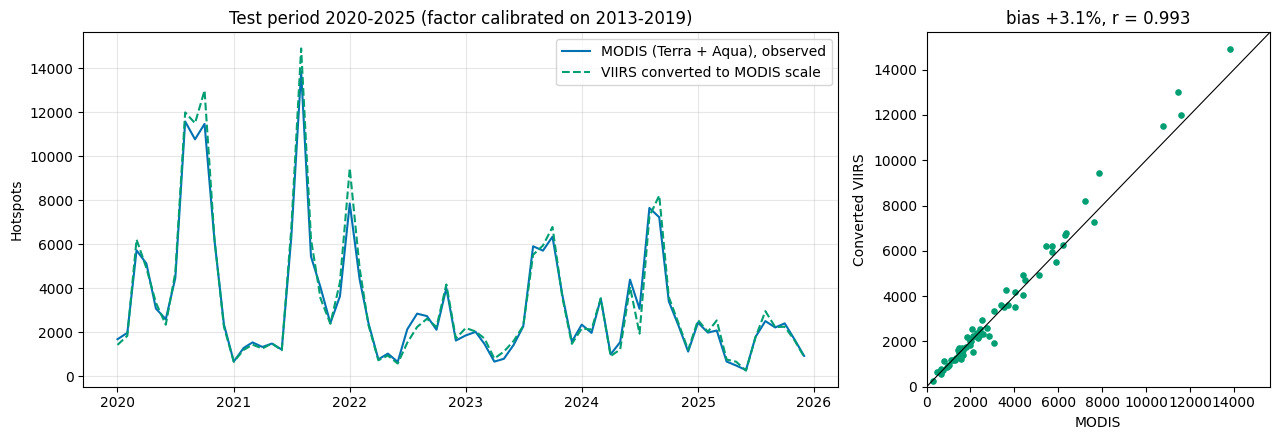

p = -0.49, c = 0.89 -> RMS = 0.94·N^-0.244


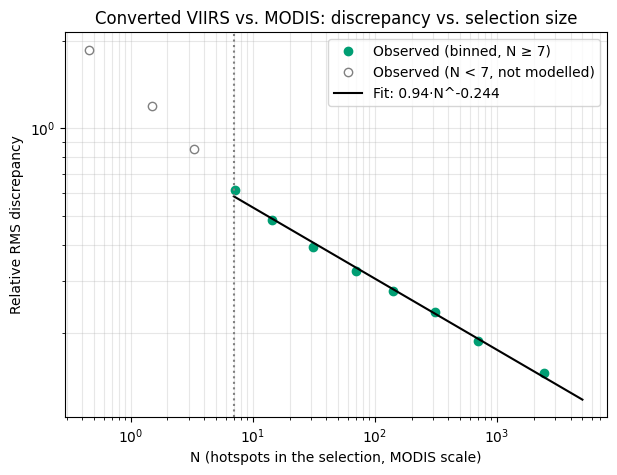

In [5]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.patches import Patch

base = Path.home() / "Downloads"
FIG = base / "figures"; FIG.mkdir(exist_ok=True)
MESES = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

arm = pd.read_csv(base / "tabla_armonizada.csv")
arm["mes"] = pd.PeriodIndex(arm["mes"], freq="M")
tabla = pd.read_csv(base / "tabla_base.csv")
tb = tabla.groupby(["cy","cx","mes","sensor"]).conteo.sum().unstack(fill_value=0).reset_index()
tb["mes"] = pd.PeriodIndex(tb["mes"], freq="M")
tb["MODIS"] = tb.MODIS_Terra + tb.MODIS_Aqua
tot = tb.groupby("mes")[["MODIS_Terra","MODIS_Aqua","VIIRS_SNPP","MODIS"]].sum()
tot = tot.reindex(pd.period_range("2000-11", tot.index.max(), freq="M"), fill_value=0)
P = lambda s: pd.Period(s, "M")

# ---- H1: raw detections per sensor ----
xx = tot.index.to_timestamp()
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(xx, tot.MODIS_Terra.where(tot.index >= P("2000-11")), label="MODIS Terra", color="#E69F00")
ax.plot(xx, tot.MODIS_Aqua.where(tot.index >= P("2002-07")), label="MODIS Aqua", color="#0072B2")
ax.plot(xx, tot.VIIRS_SNPP.where(tot.index >= P("2012-01")), label="VIIRS S-NPP (375 m)", color="#009E73")
ax.set_title("Raw monthly detections per sensor, Paraguay (after filtering, before harmonization)")
ax.set_xlabel("Month"); ax.set_ylabel("Detections"); ax.grid(alpha=0.3); ax.legend()
fig.savefig(FIG / "fig_raw_by_sensor.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- H2: harmonized national series ----
nat = arm.groupby("mes").conteo_eq.sum().reindex(tot.index, fill_value=0)
def origen(m):
    return "Terra only (estimated)" if m < P("2002-07") else ("MODIS (Terra + Aqua)" if m < P("2012-02") else "VIIRS (converted to MODIS scale)")
cols = {"Terra only (estimated)": "#E69F00", "MODIS (Terra + Aqua)": "#0072B2", "VIIRS (converted to MODIS scale)": "#009E73"}
etq = [origen(m) for m in nat.index]
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(nat.index.to_timestamp(), nat.values, width=25, color=[cols[e] for e in etq], linewidth=0)
for d0 in ["2002-07-01", "2012-02-01"]:
    ax.axvline(pd.Timestamp(d0), color="red", ls="--", lw=0.8)
ax.set_title("Harmonized national monthly series, Paraguay (MODIS scale; one sensor per period)")
ax.set_xlabel("Month"); ax.set_ylabel("Hotspots (MODIS-equivalent)")
ax.legend(handles=[Patch(color=c, label=l) for l, c in cols.items()], loc="upper right")
fig.savefig(FIG / "fig_harmonized_series.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- H3: VIIRS/MODIS ratio by calendar month and by year (2013-2025) ----
ov = tot.loc["2013-01":"2025-12"]
bm = ov.groupby(ov.index.month)[["VIIRS_SNPP", "MODIS"]].sum()
by = ov.groupby(ov.index.year)[["VIIRS_SNPP", "MODIS"]].sum()
rm, ry = bm.VIIRS_SNPP / bm.MODIS, by.VIIRS_SNPP / by.MODIS
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.bar(range(1, 13), rm.values, color="#009E73")
for i, v in enumerate(rm.values):
    a1.text(i + 1, v + 0.04, f"{v:.2f}", ha="center", fontsize=8)
a1.set_xticks(range(1, 13)); a1.set_xticklabels(MESES, fontsize=8)
a1.set_ylim(0, 4.2); a1.set_title("VIIRS / MODIS ratio by calendar month"); a1.set_ylabel("Ratio")
a2.plot(ry.index, ry.values, marker="o", color="#009E73")
a2.set_ylim(0, 4.2); a2.set_title("VIIRS / MODIS ratio by year"); a2.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "fig_ratio_viirs_modis.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- H4: out-of-sample check (factor from 2013-2019, tested on 2020-2025) ----
cal = tot.loc["2013-01":"2019-12"]
f = cal.groupby(cal.index.month).VIIRS_SNPP.sum() / cal.groupby(cal.index.month).MODIS.sum()
te = tot.loc["2020-01":"2025-12"].copy()
te["VIIRS_eq"] = te.VIIRS_SNPP.values / te.index.month.map(f).values
bias, corr = te.VIIRS_eq.sum() / te.MODIS.sum() - 1, te.VIIRS_eq.corr(te.MODIS)
print(f"bias {bias:+.1%} | r = {corr:.3f}")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
x2 = te.index.to_timestamp()
a1.plot(x2, te.MODIS, color="#0072B2", label="MODIS (Terra + Aqua), observed")
a1.plot(x2, te.VIIRS_eq, color="#009E73", ls="--", label="VIIRS converted to MODIS scale")
a1.set_title("Test period 2020-2025 (factor calibrated on 2013-2019)"); a1.set_ylabel("Hotspots"); a1.grid(alpha=0.3); a1.legend()
lim = max(te.MODIS.max(), te.VIIRS_eq.max()) * 1.05
a2.scatter(te.MODIS, te.VIIRS_eq, s=14, color="#009E73"); a2.plot([0, lim], [0, lim], color="black", lw=0.8)
a2.set_xlim(0, lim); a2.set_ylim(0, lim); a2.set_xlabel("MODIS"); a2.set_ylabel("Converted VIIRS")
a2.set_title(f"bias {bias:+.1%}, r = {corr:.3f}")
fig.tight_layout()
fig.savefig(FIG / "fig_conversion_validation.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- H5: error law (factor from 2012-02 to 2019-12, as in the uncertainty analysis) ----
cal2 = tot.loc["2012-02":"2019-12"]
f2 = cal2.groupby(cal2.index.month).VIIRS_SNPP.sum() / cal2.groupby(cal2.index.month).MODIS.sum()
meses = pd.period_range("2020-01", "2025-12", freq="M")
tt = tb[(tb.mes >= meses[0]) & (tb.mes <= meses[-1])].copy()
tt["V"] = tt.VIIRS_SNPP / tt.mes.dt.month.map(f2)
tt["M"] = tt.MODIS
filas = []
for k in [1, 2, 4, 8, 17, 34]:
    tt["by"], tt["bx"] = tt.cy // k, tt.cx // k
    g = tt.groupby(["by", "bx", "mes"])[["V", "M"]].sum()
    V = g.V.unstack(fill_value=0).reindex(columns=meses, fill_value=0)
    M = g.M.unstack(fill_value=0).reindex(columns=meses, fill_value=0)
    N = ((V + M) / 2).to_numpy().ravel(); D = (V - M).to_numpy().ravel()
    ok = N > 0
    filas.append(pd.DataFrame({"N": N[ok], "r": D[ok] / N[ok]}))
d = pd.concat(filas)
bins = [0, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 1e6]
s = d.assign(bin=pd.cut(d.N, bins)).groupby("bin", observed=True).agg(
    n=("r", "size"), N=("N", "mean"), mse=("r", lambda x: (x ** 2).mean()))
s["rms"] = np.sqrt(s.mse)
q = s[s.N >= 7]
p, lc = np.polyfit(np.log(q.N), np.log(q.mse), 1)
A_, B_ = np.sqrt(np.exp(lc)), p / 2
print(f"p = {p:.2f}, c = {np.exp(lc):.2f} -> RMS = {A_:.2f}·N^{B_:.3f}")
xs = np.logspace(np.log10(7), np.log10(5000), 100)
fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(s.N[s.N >= 7], s.rms[s.N >= 7], "o", color="#009E73", label="Observed (binned, N ≥ 7)")
ax.loglog(s.N[s.N < 7], s.rms[s.N < 7], "o", mfc="none", color="grey", label="Observed (N < 7, not modelled)")
ax.loglog(xs, A_ * xs ** B_, "k-", label=f"Fit: {A_:.2f}·N^{B_:.3f}")
ax.axvline(7, ls=":", color="grey")
ax.set_xlabel("N (hotspots in the selection, MODIS scale)"); ax.set_ylabel("Relative RMS discrepancy")
ax.set_title("Converted VIIRS vs. MODIS: discrepancy vs. selection size"); ax.grid(alpha=0.3, which="both"); ax.legend()
fig.savefig(FIG / "fig_error_law.png", dpi=150, bbox_inches="tight"); plt.show()